In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.insert(0, "../runner")
from src.riemannian_tSNE.R_tSNE import Riemannian_tSNE
from src.utils.loading import load_model
import torch
import plotly.express as px
import pandas as pd
import numpy as np
from pyriemann.utils.test import is_sym_pos_def
import hydra
import umap
from pyriemann.utils.tangentspace import upper
import matplotlib.pyplot as plt


In [3]:
model, cfg = load_model("/home/lamsade/tdesurreldesaintjulien/SPD_WFM_2/runner/logs/BNCI2014002_diffeocfm/2026-03-23_15-23-31/checkpoints/epoch_1559.ckpt")

In [4]:
dim = model.dim
device = next(model.parameters()).device
dim_TS = dim * (dim + 1) // 2
N = 100
x0 = model.sample_x0(N)
y = torch.randint(0, 2, (N,), device=device)
y_one_hot = torch.nn.functional.one_hot(y, num_classes=2).float()

In [5]:
x1_generated = model.sample_ode(x0, y_one_hot)

In [6]:
x1_generated.shape

torch.Size([100, 15, 15])

In [7]:
x0_x1 = torch.cat([x0, x1_generated], dim=0)

In [8]:
rtsne = Riemannian_tSNE(perplexity=int(2*0.75*N), verbosity=2)
emb = rtsne.fit(x0_x1)

Optimizing on cuda...
Iteration :  0
Iteration :  100
Iteration :  200
Iteration :  300
Iteration :  400
Iteration :  500
Iteration :  600
Iteration :  700
Iteration :  800
Iteration :  900
Iteration :  1000
Iteration :  1100
Iteration :  1200
Iteration :  1300
Iteration :  1400
Iteration :  1500
Iteration :  1600
Iteration :  1700
Iteration :  1800
Iteration :  1900
Min stepsize reached
Optimization done in 6.65 seconds and with 1950 iterations.
Final loss: 0.10224045166032437


In [9]:
df = pd.DataFrame(
        {
            "a": emb[:, 0, 0],
            "b": emb[:, 0, 1],
            "c": emb[:, 1, 1],
            "label" : ["original"] * N + ["generated"] * N,
            "y": torch.cat([y, y]).cpu()
        }
    )
fig = px.scatter_3d(
    df,
    x="a",
    y="b",
    z="c",
    color="label",
)
fig.show()

In [44]:
umap_ = umap.UMAP()
emb_umap = umap_.fit_transform(upper(x0_x1.cpu().numpy()))

In [45]:
emb_umap.shape

(200, 2)

Text(0.5, 1.0, 'UMAP projection of original and generated data')

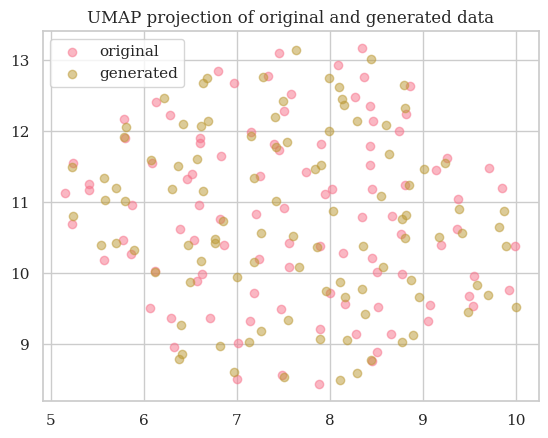

In [46]:
plt.scatter(emb_umap[:N, 0], emb_umap[:N, 1], label="original", alpha=0.5)
plt.scatter(emb_umap[N:, 0], emb_umap[N:, 1], label="generated", alpha=0.5)
plt.legend()
plt.title("UMAP projection of original and generated data")

In [10]:
datamodule = hydra.utils.instantiate(cfg.datamodule)
datamodule.setup()

Choosing from all possible events


In [11]:
x_train = datamodule.train_ds.tensors[0].numpy()
y_train = datamodule.train_ds.tensors[1].numpy()
x_val = datamodule.val_ds.tensors[0].numpy()
y_val = datamodule.val_ds.tensors[1].numpy()

In [12]:
N = x_train.shape[0]

In [13]:
from pyriemann.utils.mean import mean_riemann
from pyriemann.utils.distance import distance_riemann

In [14]:
import matplotlib.pyplot as plt


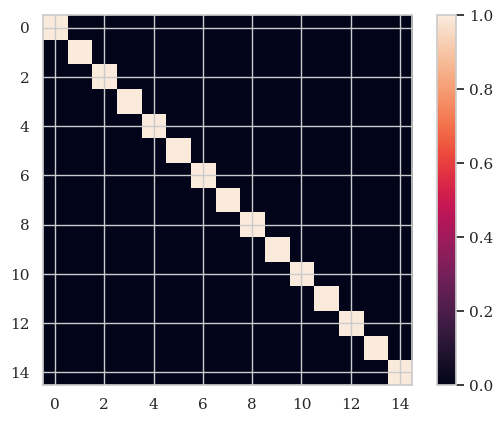

In [15]:
X_bar = mean_riemann(x_train)
plt.imshow(X_bar)
plt.colorbar()

In [16]:
X_bar_broadcast = np.broadcast_to(X_bar, x_train.shape)
var_frechet = np.mean(distance_riemann(x_train, X_bar_broadcast) ** 2)

In [17]:
var_frechet

np.float64(1.0)

In [18]:
x0 = model.sample_x0(N)

In [19]:
x0_mean = mean_riemann(x0.cpu().numpy())
X_bar_broadcast = np.broadcast_to(x0_mean, x0.shape)
var_frechet = np.mean(distance_riemann(x0.cpu().numpy(), X_bar_broadcast) ** 2)
print(var_frechet)

0.9959490073371003


In [20]:
all_cov = torch.concat([torch.tensor(x_train).to("cuda"), x0], dim=0)

In [21]:
tSNE = Riemannian_tSNE()
emb = tSNE.fit(all_cov)

Optimizing on cuda...
Iteration :  0
Iteration :  100
Iteration :  200
Iteration :  300
Iteration :  400
Iteration :  500
Iteration :  600
Iteration :  700
Iteration :  800
Iteration :  900
Iteration :  1000
Iteration :  1100
Iteration :  1200
Iteration :  1300
Iteration :  1400
Iteration :  1500
Iteration :  1600
Iteration :  1700
Iteration :  1800
Iteration :  1900
Iteration :  2000
Iteration :  2100
Iteration :  2200
Iteration :  2300
Iteration :  2400
Iteration :  2500
Iteration :  2600
Iteration :  2700
Iteration :  2800
Iteration :  2900
Iteration :  3000
Iteration :  3100
Iteration :  3200
Iteration :  3300
Iteration :  3400
Iteration :  3500
Iteration :  3600
Iteration :  3700
Iteration :  3800
Iteration :  3900
Iteration :  4000
Iteration :  4100
Iteration :  4200
Iteration :  4300
Iteration :  4400
Iteration :  4500
Iteration :  4600
Iteration :  4700
Iteration :  4800
Iteration :  4900
Iteration :  5000
Iteration :  5100
Iteration :  5200
Iteration :  5300
Optimization done 

/home/lamsade/tdesurreldesaintjulien/SPD_WFM_2/notebooks/../runner/src/riemannian_tSNE/R_tSNE.py:215: UserWarning: Time limite reached after 5307 iterations.
  warnings.warn("Time limite reached after " + str(i) + " iterations.")


In [23]:
df = pd.DataFrame(
        {
            "a": emb[:, 0, 0],
            "b": emb[:, 0, 1],
            "c": emb[:, 1, 1],
            "label" : ["original"] * N + ["generated"] * N,
            "y": torch.cat([torch.tensor(y_train), torch.tensor(y_train)]).cpu()
        }
    )
fig = px.scatter_3d(
    df,
    x="a",
    y="b",
    z="c",
    color="y",
)
fig.show()